# Q7 et Q8 : identifier les types de terroir et définir le cahier de culture
## Projet Datamining, Sujet 6 : Domaine des Trois Rivières

## Les deux questions
**Q7**. Les parcelles sont conduites de la même façon depuis trente ans. Combien de types de terroir a-t-on en réalité sur le domaine ?<br>
**Q8**. Pour chaque type, quelle conduite — densité, apports, traitements ? C'est ce qu'on veut écrire dans le cahier de culture.

## Démarche
- Explorer les variables naturelles du domaine (altitude, pente, pluviométrie, sol, exposition) et traiter les valeurs manquantes avant de regrouper les parcelles.
- Standardiser les variables numériques du terroir et tester plusieurs découpages avec k-means (méthode du coude et score de silhouette) pour choisir le nombre de terroirs.
- Décrire le profil de chaque terroir (valeurs d'origine, sols, expositions, rendement et part de premium) et sauvegarder le résultat (parcelles_terroirs.csv).
- Analyser les pratiques de conduite (densité, azote, traitements) dans chaque terroir sur les 217 parcelles valides, en comparant parcelles premium et standard.
- Définir des réglages de conduite par terroir pour le cahier de culture et vérifier leur effet sur les parcelles du domaine.

# Question 7 — Combien de types de terroir a-t-on en réalité sur le domaine ?

In [1]:
import os, pandas as pd

path = "../data/processed/parcelles_clean.csv"
df = pd.read_csv(path)


Dans un premier temps, j'analyse les 7 nombres essentiels (plus l'effectif) des 3 variables numériques du terroir :

In [2]:
num_terroir = ["altitude_m", "pente_pct", "pluviometrie_mm"]
print("Variables numériques de terroir")
display(df[num_terroir].describe().round(2))


Variables numériques de terroir


,altitude_m,pente_pct,pluviometrie_mm
count,220.00,220.00,212.00
mean,185.46,6.40,642.52
std,58.38,4.66,84.64
min,70.00,0.30,435.00
25%,146.00,2.70,586.00
50%,184.00,5.50,646.00
75%,228.25,8.52,699.00
max,340.00,28.00,895.00


On fait la répartition des types de sol et des expositions (valeurs manquantes comprises) et
on vérifie si certaines catégories sont très rares et combien de parcelles sont incomplètes, afin de décider comment les traiter avant de regrouper les terroirs.

In [3]:
cat_terroir = ["type_sol", "exposition"]
for col in cat_terroir:
    print(f"\n{col}")
    eff = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(dropna=False, normalize=True) * 100).round(1)
    display(pd.DataFrame({"effectif": eff, "part_%": pct}))


type_sol


,effectif,part_%
type_sol,,
argilo-calcaire,69,31.4
sableux,58,26.4
caillouteux,52,23.6
limoneux,41,18.6



exposition


,effectif,part_%
exposition,,
sud,74,33.6
sud-est,65,29.5
est,52,23.6
nord,21,9.5
NaN,8,3.6


Maintenant, on regarde l'altitude, la pente et la pluie avec des boîtes à moustaches pour voir où vit la majorité des parcelles et vérifier si celles qui sortent du lot ne forment pas déjà un terroir particulier

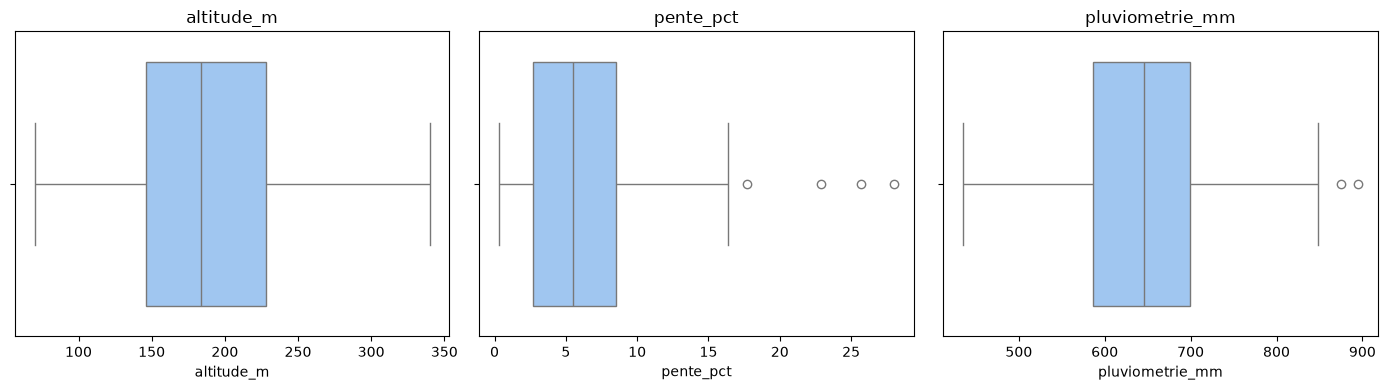

 altitude_m : seuils [22.6 ; 351.6] -> 0 parcelles au-delà
 pente_pct : seuils [-6.0 ; 17.3] -> 4 parcelles au-delà
 pluviometrie_mm : seuils [416.5 ; 868.5] -> 2 parcelles au-delà


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_terroir):
    sns.boxplot(x=df[col], ax=ax, color="#93c5fd")
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in num_terroir:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    seuil_bas = q1 - 1.5 * iqr
    seuil_haut = q3 + 1.5 * iqr
    
    extremes = df[(df[col] < seuil_bas) | (df[col] > seuil_haut)]
    print(f" {col} : seuils [{seuil_bas:.1f} ; {seuil_haut:.1f}] -> {len(extremes)} parcelles au-delà")
    

Maintenant, on compare nos variables de terroir entre elles, on regarde si chaque type de sol, chaque exposition correspond déjà à une altitude, une pente ou une pluie particulière.
On découpe aussi l'altitude et la pente en tranches simples pour repérer des écarts qu'une moyenne globale écraserait.

In [5]:
print("Moyennes du terroir par type de sol")
display(df.groupby("type_sol")[num_terroir].mean().round(1))

print("Moyennes du terroir par exposition")
display(df.groupby("exposition")[num_terroir].mean().round(1))

print("Croisement type de sol x exposition")
display(pd.crosstab(df["type_sol"], df["exposition"], margins=True))

df_temp = df.copy()
df_temp["tranche_altitude"] = pd.cut(
    df_temp["altitude_m"],
    bins=[0, 140, 185, 230, 400],
    labels=["< 140 m", "140 - 185 m", "185 - 230 m", "> 230 m"]
)
df_temp["tranche_pente"] = pd.cut(
    df_temp["pente_pct"],
    bins=[0, 3, 6, 10, 35],
    labels=["Plat (< 3%)", "Doux (3-6%)", "Coteau (6-10%)", "Fort (> 10%)"]
)

print("Répartition des sols (%) par tranche d'altitude")
display((pd.crosstab(df_temp["tranche_altitude"], df_temp["type_sol"], normalize="index") * 100).round(1))

print("Répartition des sols (%) par tranche de pente")
display((pd.crosstab(df_temp["tranche_pente"], df_temp["type_sol"], normalize="index") * 100).round(1))

Moyennes du terroir par type de sol


,altitude_m,pente_pct,pluviometrie_mm
type_sol,,,
argilo-calcaire,182.8,6.9,659.3
caillouteux,182.0,5.8,636.1
limoneux,196.4,6.0,635.7
sableux,184.0,6.7,632.9


Moyennes du terroir par exposition


,altitude_m,pente_pct,pluviometrie_mm
exposition,,,
est,188.5,5.8,641.9
nord,175.9,6.2,633.2
sud,186.4,5.6,639.9
sud-est,184.4,7.6,644.0


Croisement type de sol x exposition


exposition,est,nord,sud,sud-est,All
type_sol,,,,,
argilo-calcaire,10,5,26,22,63
caillouteux,12,6,17,17,52
limoneux,11,2,15,13,41
sableux,19,8,16,13,56
All,52,21,74,65,212


Répartition des sols (%) par tranche d'altitude


type_sol,argilo-calcaire,caillouteux,limoneux,sableux
tranche_altitude,,,,
< 140 m,23.4,29.8,17.0,29.8
140 - 185 m,40.9,16.7,15.2,27.3
185 - 230 m,31.5,24.1,14.8,29.6
> 230 m,26.4,26.4,28.3,18.9


Répartition des sols (%) par tranche de pente


type_sol,argilo-calcaire,caillouteux,limoneux,sableux
tranche_pente,,,,
Plat (< 3%),30.6,29.0,16.1,24.2
Doux (3-6%),28.1,28.1,21.1,22.8
Coteau (6-10%),31.2,18.8,21.9,28.1
Fort (> 10%),37.8,16.2,13.5,32.4


,altitude_m,pente_pct,pluviometrie_mm,est_ouest_km,nord_sud_km,rendement_kg_ha
altitude_m,1.00,-0.04,0.02,0.07,0.08,-0.21
pente_pct,-0.04,1.00,-0.13,-0.01,0.09,-0.34
pluviometrie_mm,0.02,-0.13,1.00,-0.06,-0.11,0.38
est_ouest_km,0.07,-0.01,-0.06,1.00,0.06,0.07
nord_sud_km,0.08,0.09,-0.11,0.06,1.00,-0.09
rendement_kg_ha,-0.21,-0.34,0.38,0.07,-0.09,1.00


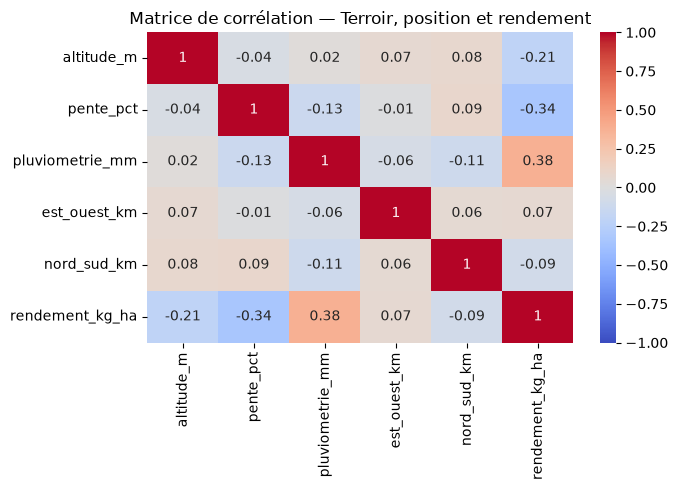

Rendement moyen par type de sol :


,count,mean,median
type_sol,,,
argilo-calcaire,69,6715.7,6770.0
caillouteux,50,6996.3,6946.5
limoneux,41,6503.5,6484.0
sableux,57,6579.4,6617.0


In [6]:
df_valide = df[~df["rendement_nul_a_verifier"]]

cols_corr = ["altitude_m", "pente_pct", "pluviometrie_mm", "est_ouest_km", "nord_sud_km", "rendement_kg_ha"]
mat_corr = df_valide[cols_corr].corr().round(2)

display(mat_corr)

plt.figure(figsize=(7, 5))
sns.heatmap(mat_corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation — Terroir, position et rendement")
plt.tight_layout()
plt.show()

print("Rendement moyen par type de sol :")
display(df_valide.groupby("type_sol")["rendement_kg_ha"].agg(["count", "mean", "median"]).round(1))

Après analyse de ces données, voici mes hypothèses avant de lancer un algorithme :

- **H1 :** le relief et la pluie varient indépendamment du type de sol (moyennes d'altitude de 182 à 196 m, de pente de 5,8 à 6,9 % et de pluie de 633 à 659 mm selon le sol, avec des corrélations entre variables physiques quasi nulles de -0,13 à +0,02). Comme k-means repose sur des distances euclidiennes, j'exclus le sol et l'exposition du calcul pour ne pas écraser les 3 variables continues par des indicatrices binaires sur 220 parcelles. Je vérifierai ensuite comment les sols (qui pèsent tout de même sur le rendement, notamment caillouteux vs limoneux) et les expositions se répartissent dans chaque zone.
- **H2 :** le relief et la pluie jouent un vrai rôle sur le rendement (pluie +0,38, pente -0,34, altitude -0,21) et les parcelles très pentues (4 parcelles au-delà de 17,3 %) correspondent à un profil réel plutôt qu'à des erreurs. Je les conserve dans le calcul.
- **H3 :** les conditions naturelles ne suivent pas la carte géographique (corrélations de -0,11 à +0,09 avec `est_ouest_km` et `nord_sud_km`). Je teste plusieurs valeurs de k pour voir si des groupes naturels se détachent ou s'il s'agit plutôt d'un continuum à découper en zones de gestion.

Je cherche à regrouper les parcelles selon leur terroir sans avoir de réponse connue à l'avance : c'est un problème non supervisé, j'utilise donc l'algorithme k-means vu en cours. Je laisse volontairement le rendement, le classement et la conduite (densité, azote, traitements) en dehors du calcul pour ne pas fausser les terroirs.Comme k-means calcule des distances sur des valeurs numériques, je travaille sur les 3 variables chiffrées du terroir (altitude_m, pente_pct, pluviometrie_mm) et je vérifierai ensuite le lien avec le type de sol et l'exposition.

Comme la pluie n'est presque pas liée à la position (-0,06 et -0,11) ni à l'altitude (0,02), je remplace simplement les 8 valeurs manquantes par la médiane (646 mm).

Je standardise les 3 colonnes avec StandardScaler pour qu'elles aient toutes une moyenne de 0 et un écart-type de 1 sinon la pluie (435 à 895 mm) et l'altitude (70 à 340 m) écraseraient la pente (0,3 à 28 %) dans le calcul des distances. Il n'y a pas de découpage apprentissage/test en non supervisé, donc je standardise tout le tableau directement.

In [7]:
from sklearn.preprocessing import StandardScaler

colonnes_terroir = ["altitude_m", "pente_pct", "pluviometrie_mm"]

df_km = df[colonnes_terroir].copy()
df_km["pluviometrie_mm"] = df_km["pluviometrie_mm"].fillna(df_km["pluviometrie_mm"].median())

X = StandardScaler().fit_transform(df_km)

print("Moyennes après standardisation :", X.mean(axis=0).round(3))
print("Écarts-types après standardisation :", X.std(axis=0).round(3))

Moyennes après standardisation : [-0. -0.  0.]
Écarts-types après standardisation : [1. 1. 1.]


Comme k-means impose de fixer k à l'avance, je teste plusieurs découpages avec n_init=10 (10 lancements pour garder l'inertie la plus basse). Pour choisir k, je croise la méthode du coude 
(k=1 à 8, via l'inertie et son gain d'un k au suivant) pour la compacité, 
et le score de silhouette (k=2 à 8, proche de 1) pour la séparation.

,k,inertie,gain_inertie,silhouette
0,1,660.0,NaN,NaN
1,2,495.9,164.1,0.245
2,3,386.1,109.8,0.259
3,4,303.0,83.0,0.267
4,5,262.9,40.1,0.259
5,6,233.2,29.8,0.270
6,7,209.0,24.2,0.275
7,8,195.7,13.3,0.274


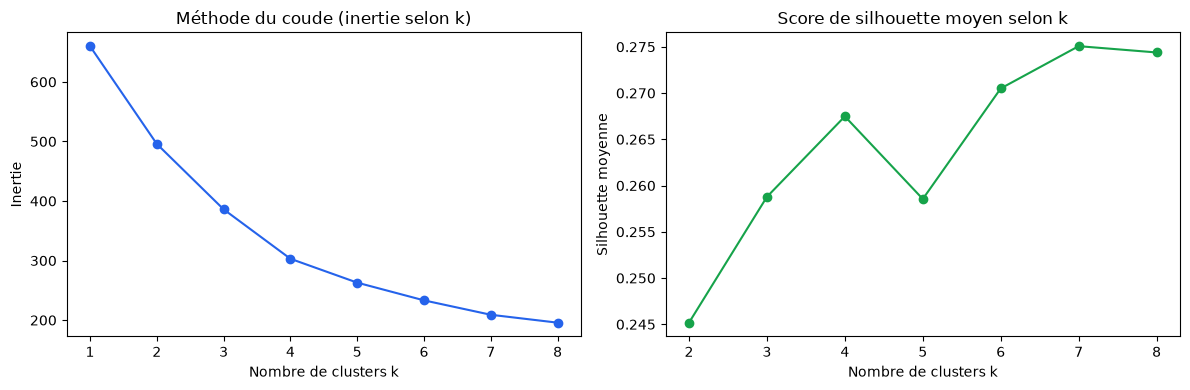

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

inerties = []
for k in range(1, 9):
    modele = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inerties.append(modele.inertia_)

gains = [np.nan] + [inerties[i - 1] - inerties[i] for i in range(1, len(inerties))]

silhouettes = [np.nan]
for k in range(2, 9):
    etiquettes = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    silhouettes.append(silhouette_score(X, etiquettes))

res_k = pd.DataFrame({
    "k": range(1, 9),
    "inertie": np.round(inerties, 1),
    "gain_inertie": np.round(gains, 1),
    "silhouette": np.round(silhouettes, 3)
})
display(res_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 9), inerties, marker="o", color="#2563eb")
axes[0].set_title("Méthode du coude (inertie selon k)")
axes[0].set_xlabel("Nombre de clusters k")
axes[0].set_ylabel("Inertie")

axes[1].plot(range(2, 9), silhouettes[1:], marker="o", color="#16a34a")
axes[1].set_title("Score de silhouette moyen selon k")
axes[1].set_xlabel("Nombre de clusters k")
axes[1].set_ylabel("Silhouette moyenne")

plt.tight_layout()
plt.show()

La méthode du coude désigne k = 4, le gain d'inertie chute de moitié juste après (de 83,0 à 40,1), donc ajouter des groupes ne fait presque plus gagner de compacité. Le score de silhouette reste modeste (0,245 à 0,275), ce qui indique un terrain continu plutôt que des blocs totalement isolés. Il atteint toutefois un premier pic à k = 4 (0,267) avant de redescendre à k = 5 (0,259), même si k = 7 monte légèrement (0,275), je retiens 4 terroirs, un découpage cohérent et gérable sur le domaine. 

Je calcule maintenant le profil de chaque terroir sur les valeurs d'origine (non standardisées), puis je regarde après coup comment le sol, l'exposition, le rendement et le classement se répartissent dans chaque groupe.

Parcelles à la frontière (silhouette < 0) : 8 sur 220
Profil des 4 zones de gestion (valeurs d'origine) :


,nb_parcelles,altitude_m,pente_pct,pluviometrie_mm,rendement_moy,part_premium_%
nom_terroir,,,,,,
Coteaux pentus,35,177.3,14.7,607.5,6054.0,82.9
Hauts plateaux secs,69,239.5,4.5,619.6,6675.0,66.2
Basses plaines sèches,60,131.2,4.8,592.5,6814.0,57.6
Terres humides,56,182.1,5.2,741.6,7038.0,52.7


Répartition des sols (%) par zone :


type_sol,argilo-calcaire,caillouteux,limoneux,sableux
nom_terroir,,,,
Basses plaines sèches,25.0,28.3,18.3,28.3
Coteaux pentus,37.1,17.1,11.4,34.3
Hauts plateaux secs,26.1,29.0,27.5,17.4
Terres humides,41.1,16.1,12.5,30.4


Répartition des expositions (%) par zone :


exposition,est,nord,sud,sud-est
nom_terroir,,,,
Basses plaines sèches,21.7,11.7,38.3,28.3
Coteaux pentus,20.6,5.9,20.6,52.9
Hauts plateaux secs,25.4,9.0,41.8,23.9
Terres humides,29.4,11.8,31.4,27.5


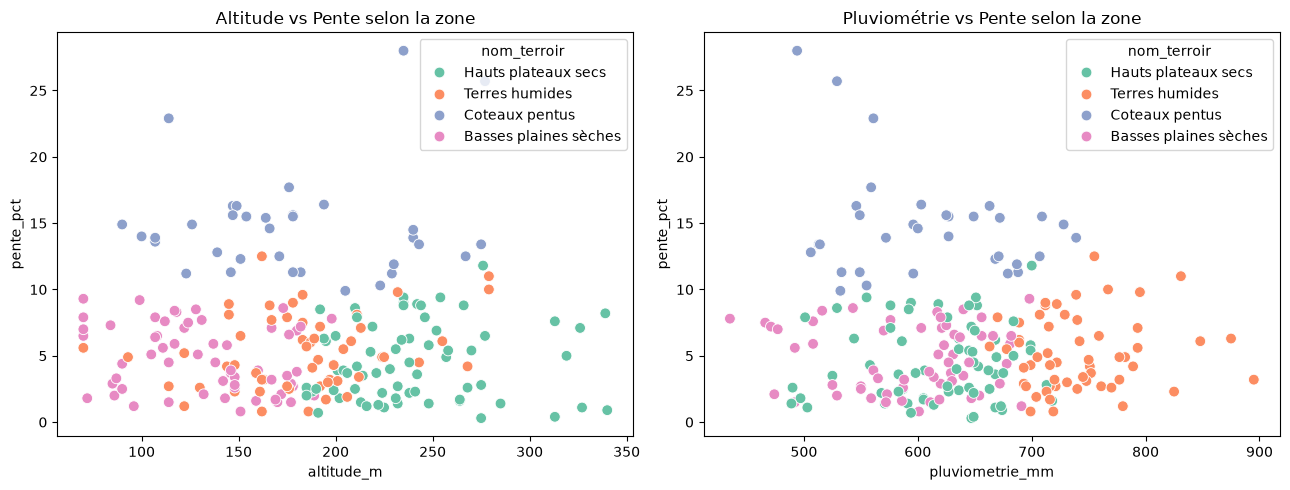

Fichier sauvegardé : ../data/processed/parcelles_terroirs.csv


In [9]:
from sklearn.metrics import silhouette_samples


modele_final = KMeans(n_clusters=4, n_init=10, random_state=42)
df["terroir"] = modele_final.fit_predict(X)
df["silhouette_parcelle"] = silhouette_samples(X, df["terroir"])

print("Parcelles à la frontière (silhouette < 0) :", (df["silhouette_parcelle"] < 0).sum(), "sur", len(df))

# Attribution automatique des noms à partir des moyennes de chaque cluster
centres = df.groupby("terroir")[colonnes_terroir].mean()
id_coteaux = centres["pente_pct"].idxmax()
id_humides = centres.drop(index=id_coteaux)["pluviometrie_mm"].idxmax()
restants = centres.drop(index=[id_coteaux, id_humides])
id_plateaux = restants["altitude_m"].idxmax()
id_plaines = restants["altitude_m"].idxmin()

noms_terroirs = {
    id_coteaux: "Coteaux pentus",
    id_humides: "Terres humides",
    id_plateaux: "Hauts plateaux secs",
    id_plaines: "Basses plaines sèches"
}

assert len(noms_terroirs) == 4
assert centres.loc[id_coteaux, "pente_pct"] > 10
assert centres.loc[id_humides, "pluviometrie_mm"] > 700
assert centres.loc[id_plateaux, "altitude_m"] > centres.loc[id_plaines, "altitude_m"]

df["nom_terroir"] = df["terroir"].map(noms_terroirs)

df_valide = df[~df["rendement_nul_a_verifier"]].copy()

bilan = df.groupby("nom_terroir")[colonnes_terroir].mean().round(1)
bilan.insert(0, "nb_parcelles", df["nom_terroir"].value_counts())
bilan["rendement_moy"] = df_valide.groupby("nom_terroir")["rendement_kg_ha"].mean().round(0)
bilan["part_premium_%"] = (
    df_valide.groupby("nom_terroir")["classement_recolte"]
    .apply(lambda s: (s == "premium").mean() * 100)
    .round(1)
)
print("Profil des 4 zones de gestion (valeurs d'origine) :")
display(bilan.sort_values("rendement_moy"))

print("Répartition des sols (%) par zone :")
display((pd.crosstab(df["nom_terroir"], df["type_sol"], normalize="index") * 100).round(1))

print("Répartition des expositions (%) par zone :")
display((pd.crosstab(df["nom_terroir"], df["exposition"], normalize="index") * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df, x="altitude_m", y="pente_pct",
    hue="nom_terroir", palette="Set2", s=60, ax=axes[0]
)
axes[0].set_title("Altitude vs Pente selon la zone")

sns.scatterplot(
    data=df, x="pluviometrie_mm", y="pente_pct",
    hue="nom_terroir", palette="Set2", s=60, ax=axes[1]
)
axes[1].set_title("Pluviométrie vs Pente selon la zone")

plt.tight_layout()
plt.show()

df.to_csv("../data/processed/parcelles_terroirs.csv", index=False)
print("Fichier sauvegardé : ../data/processed/parcelles_terroirs.csv")

**Bilan des hypothèses Q7 :**
- **H1 confirmée :** le clustering sur les 3 variables physiques laisse tous les sols présents dans chaque zone (avec toutefois plus d'argilo-calcaire en Terres humides à 41,1 % et plus d'exposition sud-est sur les Coteaux pentus à 52,9 %). Le sol reste un facteur complémentaire à suivre sur le rendement.
- **H2 confirmée :** les parcelles les plus pentues forment une zone bien identifiée (Coteaux pentus, 14,7 % de pente moyenne). Son taux de premium élevé (82,9 %) s'explique avant tout par son rendement moyen plus bas (6 054 kg/ha).
- **H3 nuancée :** le test sur données mélangées (silhouette ~0,268 contre 0,267 sur les données réelles) montre qu'il n'existe pas de terroirs naturellement séparés, mais un continuum. En revanche, le découpage en 4 zones est stable d'un lancement à l'autre (ARI >= 0,86) et fournit 4 zones de gestion exploitables pour le cahier de culture.

# Question 8 — Pour chaque type, quelle conduite — densité, apports, traitements ?

Je repars des 4 terroirs identifiés à la question 7 (parcelles_terroirs.csv) pour analyser les pratiques de conduite et voir comment optimiser le rendement et la qualité (premium) sur chaque groupe. Je commence par vérifier le tableau enrichi et les éventuelles valeurs manquantes.

In [10]:
df = pd.read_csv("../data/processed/parcelles_terroirs.csv")
print("Dimensions :", df.shape)
print("Colonnes :", list(df.columns))

print("\nValeurs manquantes par colonne :")
display(df.isna().sum()[df.isna().sum() > 0])

display(df.head())

Dimensions : (220, 20)
Colonnes : ['parcelle_id', 'surface_ha', 'cepage', 'age_vignes_ans', 'type_sol', 'altitude_m', 'pente_pct', 'exposition', 'densite_pieds_ha', 'pluviometrie_mm', 'azote_apporte_g_ha', 'traitements_an', 'est_ouest_km', 'nord_sud_km', 'rendement_kg_ha', 'classement_recolte', 'rendement_nul_a_verifier', 'terroir', 'silhouette_parcelle', 'nom_terroir']

Valeurs manquantes par colonne :


exposition         8
pluviometrie_mm    8
dtype: int64

,parcelle_id,surface_ha,cepage,age_vignes_ans,type_sol,altitude_m,pente_pct,exposition,densite_pieds_ha,pluviometrie_mm,azote_apporte_g_ha,traitements_an,est_ouest_km,nord_sud_km,rendement_kg_ha,classement_recolte,rendement_nul_a_verifier,terroir,silhouette_parcelle,nom_terroir
0,P150,0.70,syrah,31.0,argilo-calcaire,242.0,3.6,sud,3778.0,668.0,29396.0,2,3.89,7.34,7149.0,standard,False,0,0.300704,Hauts plateaux secs
1,P75,0.73,syrah,22.0,sableux,235.0,9.0,nord,3903.0,594.0,47287.0,3,8.02,2.68,6580.0,premium,False,0,0.289775,Hauts plateaux secs
2,P105,1.73,syrah,17.0,limoneux,243.0,4.5,sud-est,4052.0,722.0,9632.0,7,2.15,3.35,5825.0,premium,False,3,0.059014,Terres humides
3,P32,1.31,grenache,5.0,limoneux,276.0,11.8,sud-est,4212.0,700.0,39640.0,7,4.97,6.99,6887.0,premium,False,0,0.090515,Hauts plateaux secs
4,P73,0.66,syrah,2.0,caillouteux,268.0,4.2,sud-est,5186.0,789.0,24436.0,3,8.60,1.21,7300.0,standard,False,3,0.177544,Terres humides


Je commence par écarter les 3 parcelles à rendement nul (rendement_nul_a_verifier) pour ne pas fausser l'analyse de la récolte. J'observe ensuite les 7 nombres essentiels et les boîtes à moustaches des 3 variables de conduite (densite_pieds_ha, azote_apporte_g_ha, traitements_an) ainsi que la répartition des classements de récolte.


Indicateurs des variables de conduite et du rendement :


,densite_pieds_ha,azote_kg_ha,traitements_an,rendement_kg_ha
count,217.0,217.0,217.0,217.0
mean,4200.5,37.7,6.2,6704.5
std,482.2,11.0,2.4,973.8
min,2963.0,9.6,1.0,4483.0
25%,3869.0,29.8,5.0,6049.0
50%,4219.0,38.2,6.0,6770.0
75%,4588.0,45.6,8.0,7368.0
max,5302.0,74.7,15.0,9438.0


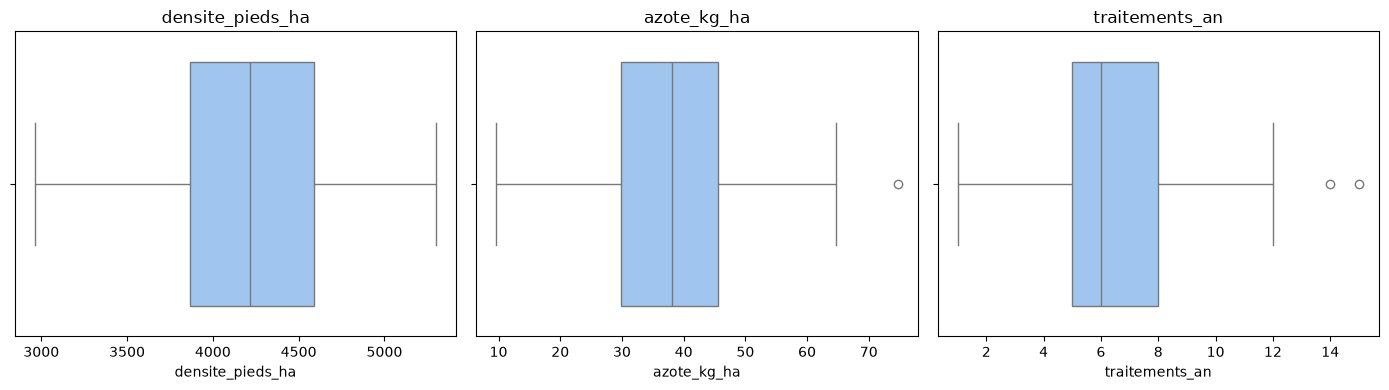

In [11]:
df_q8 = df[~df["rendement_nul_a_verifier"]].copy()
df_q8["azote_kg_ha"] = (df_q8["azote_apporte_g_ha"] / 1000).round(2)
cols_conduite = ["densite_pieds_ha", "azote_kg_ha", "traitements_an"]
print("\nIndicateurs des variables de conduite et du rendement :")
display(df_q8[cols_conduite + ["rendement_kg_ha"]].describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cols_conduite):
    sns.boxplot(x=df_q8[col], ax=ax, color="#93c5fd")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Maintenant je regarde comment la densité, l'azote et les traitements varient entre les parcelles premium et les autres dans chaque terroir puis je vérifie leur corrélation avec le rendement. Cela permet de voir si une conduite marche partout ou si chaque terroir a besoin de ses propres réglages.

In [12]:
print("Conduite moyenne par terroir (toutes parcelles valides) :")
display(df_q8.groupby("nom_terroir")[cols_conduite].mean().round(1))

print("Conduite moyenne par terroir et classement :")
comp = df_q8.groupby(["nom_terroir", "classement_recolte"]).agg(
    nb_parcelles=("parcelle_id", "count"),
    densite_moy=("densite_pieds_ha", "mean"),
    azote_moy=("azote_apporte_g_ha", "mean"),
    traitements_moy=("traitements_an", "mean"),
    rendement_moy=("rendement_kg_ha", "mean")
).round(1)
display(comp)

print("Corrélation de la conduite avec le rendement (global) :")
display(df_q8[cols_conduite + ["rendement_kg_ha"]].corr()[["rendement_kg_ha"]].round(2))

print("Corrélation de la conduite avec le rendement PAR TERROIR :")
corr_terroir = {}
for t, groupe in df_q8.groupby("nom_terroir"):
    corr_terroir[t] = groupe[cols_conduite].corrwith(groupe["rendement_kg_ha"]).round(2)
display(pd.DataFrame(corr_terroir).T)

Conduite moyenne par terroir (toutes parcelles valides) :


,densite_pieds_ha,azote_kg_ha,traitements_an
nom_terroir,,,
Basses plaines sèches,4167.6,37.7,6.0
Coteaux pentus,4185.5,38.1,6.7
Hauts plateaux secs,4227.7,38.2,6.1
Terres humides,4211.9,36.9,6.2


Conduite moyenne par terroir et classement :


nb_parcelles  densite_moy  \
nom_terroir           classement_recolte                              
Basses plaines sèches premium                       34       4227.8   
                      standard                      25       4085.7   
Coteaux pentus        premium                       29       4176.3   
                      standard                       6       4230.2   
Hauts plateaux secs   premium                       45       4235.2   
                      standard                      23       4213.1   
Terres humides        premium                       29       4240.3   
                      standard                      26       4180.1   

                                          azote_moy  traitements_moy  \
nom_terroir           classement_recolte                               
Basses plaines sèches premium               31681.7              6.3   
                      standard              45902.7              5.6   
Coteaux pentus        premium               35383.2              6.7   
                      standard              50988.8              7.0   
Hauts plateaux secs   premium               34512.3              6.2   
                      standard              45440.4              5.9   
Terres humides        premium               31810.4              6.3   
                      standard              42543.2              6.2   

                                          rendement_moy  
nom_terroir           classement_recolte                 
Basses plaines sèches premium                    6184.1  
                      standard                   7670.3  
Coteaux pentus        premium                    5742.4  
                      standard                   7557.5  
Hauts plateaux secs   premium                    6149.6  
                      standard                   7703.9  
Terres humides        premium                    6386.9  
                      standard                   7763.2

Corrélation de la conduite avec le rendement (global) :


,rendement_kg_ha
densite_pieds_ha,0.07
azote_kg_ha,0.58
traitements_an,-0.01
rendement_kg_ha,1.00


Corrélation de la conduite avec le rendement PAR TERROIR :


,densite_pieds_ha,azote_kg_ha,traitements_an
Basses plaines sèches,0.18,0.63,-0.11
Coteaux pentus,0.24,0.78,0.13
Hauts plateaux secs,-0.04,0.52,0.10
Terres humides,-0.02,0.65,-0.03


Le tableau de conduite moyenne confirme directement la prémisse de la question 7 : les 4 zones reçoivent aujourd'hui quasiment les mêmes pratiques (azote moyen compris entre 36,9 et 38,2 kg/ha, densité entre 4 168 et 4 228 pieds/ha, traitements entre 6,0 et 6,7 passages/an). Les parcelles sont bien conduites de la même façon malgré des conditions naturelles différentes.

**H1** : Je pense que l'azote est le levier principal entre standard et premium, avec un dosage propre à chaque terroir car sa corrélation au rendement atteint +0,52 à +0,78, et les parcelles standard en reçoivent 10 700 à 15 600 g/ha de plus que les premium (31 810 g/ha en Terres humides contre 35 383 en Coteaux pentus). Pour le prouver, je découpe l'azote en tranches par terroir pour repérer le seuil à ne pas dépasser.<br>

**H2** : Je pense qu'il existe un seuil direct entre fort rendement et qualité premium puisque dans tous les terroirs, les premium produisent en moyenne 5 742 à 6 387 kg/ha, contre 7 558 à 7 763 kg/ha pour les standard. Je vais examiner la distribution exacte des rendements entre les deux classements.<br>

**H3** : Je pense que la densité et les traitements jouent peu, ou cachent une zone optimale non linéaire car leurs corrélations globales au rendement sont quasi nulles (+0,07 et -0,01) et leurs moyennes varient peu entre premium et standard. Donc j'observe le taux de premium et le rendement par tranches dans chaque terroir.<br>

Rendement min / médiane / max selon le classement


,count,min,median,max
classement_recolte,,,,
premium,137,4483.0,6241.0,6997.0
standard,80,7003.0,7578.0,9438.0


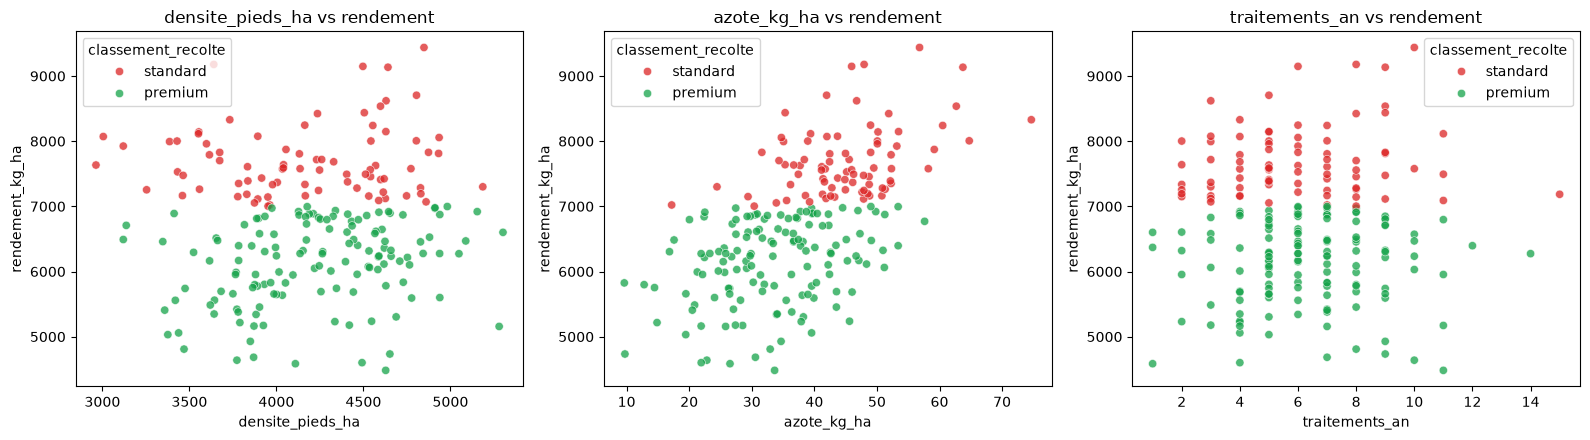

Part de premium (%) par terroir selon : Azote (g/ha)


tranche_azote,< 25k,25k - 35k,35k - 45k,> 45k
nom_terroir,,,,
Basses plaines sèches,100.0,88.2,44.4,18.8
Coteaux pentus,100.0,93.3,100.0,61.5
Hauts plateaux secs,100.0,94.1,60.0,33.3
Terres humides,75.0,77.8,55.6,9.1


Part de premium (%) par terroir selon : Densité (pieds/ha)


tranche_densite,< 3800,3800 - 4200,4200 - 4600,> 4600
nom_terroir,,,,
Basses plaines sèches,50.0,50.0,66.7,63.6
Coteaux pentus,83.3,84.6,83.3,80.0
Hauts plateaux secs,60.0,80.0,59.1,68.8
Terres humides,50.0,50.0,64.3,46.2


Part de premium (%) par terroir selon : Traitements / an


tranche_trait,1 - 4,5 - 6,7 - 8,> 8
nom_terroir,,,,
Basses plaines sèches,47.1,61.1,56.2,75.0
Coteaux pentus,83.3,88.9,90.9,66.7
Hauts plateaux secs,50.0,72.4,76.9,60.0
Terres humides,50.0,50.0,52.9,60.0


In [13]:
print("Rendement min / médiane / max selon le classement")
display(df_q8.groupby("classement_recolte")["rendement_kg_ha"].agg(["count", "min", "median", "max"]).round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, cols_conduite):
    sns.scatterplot(
        data=df_q8, x=col, y="rendement_kg_ha",
        hue="classement_recolte", palette={"premium": "#16a34a", "standard": "#dc2626"},
        alpha=0.75, ax=ax
    )
    ax.set_title(f"{col} vs rendement")
plt.tight_layout()
plt.show()

df_tmp = df_q8.copy()
df_tmp["tranche_azote"] = pd.cut(
    df_tmp["azote_apporte_g_ha"],
    bins=[0, 25000, 35000, 45000, 80000],
    labels=["< 25k", "25k - 35k", "35k - 45k", "> 45k"]
)
df_tmp["tranche_densite"] = pd.cut(
    df_tmp["densite_pieds_ha"],
    bins=[0, 3800, 4200, 4600, 6000],
    labels=["< 3800", "3800 - 4200", "4200 - 4600", "> 4600"]
)
df_tmp["tranche_trait"] = pd.cut(
    df_tmp["traitements_an"],
    bins=[0, 4, 6, 8, 20],
    labels=["1 - 4", "5 - 6", "7 - 8", "> 8"]
)

for col_t, titre in [
    ("tranche_azote", "Azote (g/ha)"),
    ("tranche_densite", "Densité (pieds/ha)"),
    ("tranche_trait", "Traitements / an")
]:
    print(f"Part de premium (%) par terroir selon : {titre}")
    tab = (
        df_tmp.assign(is_prem=df_tmp["classement_recolte"] == "premium")
        .pivot_table(index="nom_terroir", columns=col_t, values="is_prem", aggfunc="mean", observed=False) * 100
    ).round(1)
    display(tab)

Les parcelles premium ont toutes un rendement inférieur à 7 000 kg/ha. L'azote semble être le principal facteur influençant ce classement, contrairement à la densité et aux traitements. Je vais donc analyser les 4 terroirs séparément pour identifier les doses d'azote les plus adaptées et comparer les pratiques des parcelles premium.

In [14]:
from sklearn.linear_model import LinearRegression
ordre_terroirs = ["Coteaux pentus", "Hauts plateaux secs", "Basses plaines sèches", "Terres humides"]
plafonds_azote_kg = {
    "Coteaux pentus": 45,
    "Hauts plateaux secs": 38,
    "Basses plaines sèches": 35,
    "Terres humides": 32
}

res_reg = []
for terroir in ordre_terroirs:
    sub = df_q8[df_q8["nom_terroir"] == terroir]
    reg = LinearRegression().fit(sub[["azote_kg_ha"]], sub["rendement_kg_ha"])
    pente = reg.coef_[0]
    intercept = reg.intercept_
    dose_6900 = (6900 - intercept) / pente
    res_reg.append({
        "zone": terroir,
        "gain_kg_par_kgN": round(pente, 1),
        "dose_moy_6900_kgN_ha": round(dose_6900, 1),
        "plafond_securite_kgN_ha": plafonds_azote_kg[terroir]
    })

print("Régression linéaire rendement ~ azote par zone :")
display(pd.DataFrame(res_reg))

Régression linéaire rendement ~ azote par zone :


,zone,gain_kg_par_kgN,dose_moy_6900_kgN_ha,plafond_securite_kgN_ha
0,Coteaux pentus,61.8,51.8,45
1,Hauts plateaux secs,47.0,43.0,38
2,Basses plaines sèches,54.4,39.3,35
3,Terres humides,50.7,34.2,32


In [15]:
df_hist = pd.read_csv("../data/processed/historique_clean.csv")
col_annee = "annee" if "annee" in df_hist.columns else [c for c in df_hist.columns if "an" in c.lower() or "mill" in c.lower()][0]

if "classement_recolte" not in df_hist.columns:
    df_hist = df_hist.merge(df_q8[["parcelle_id", "classement_recolte"]], on="parcelle_id", how="inner")

print("Prix moyen (EUR/kg) par année et classement :")
prix_par_an = df_hist.pivot_table(
    index=col_annee, columns="classement_recolte", values="prix_kg_eur", aggfunc="mean"
).round(3)
display(prix_par_an)

derniere_annee = df_hist[col_annee].max()
prix_moy_recent = df_hist[df_hist[col_annee] == derniere_annee]["prix_kg_eur"].mean()
print(f"Prix moyen en {derniere_annee} : {prix_moy_recent:.2f} EUR/kg")

Prix moyen (EUR/kg) par année et classement :


classement_recolte,premium,standard
millesime,,
2019,1.889,1.910
2020,1.876,1.928
2021,1.856,1.947
2022,1.812,1.924
2023,1.883,1.922
2024,1.872,1.854


Prix moyen en 2024 : 1.87 EUR/kg


In [16]:
df_check = df_q8.copy()
df_check["plafond_azote_kg"] = df_check["nom_terroir"].map(plafonds_azote_kg)
df_check["azote_ok"] = df_check["azote_kg_ha"] <= df_check["plafond_azote_kg"]
df_check["conforme_cahier"] = (
    df_check["azote_ok"]
    & df_check["densite_pieds_ha"].between(3900, 4600)
    & df_check["traitements_an"].between(5, 8)
)

print("Parcelles déjà sous le plafond d'azote seul :")
bilan_azote = df_check.groupby("azote_ok").agg(
    nb_parcelles=("parcelle_id", "count"),
    rendement_moy=("rendement_kg_ha", "mean"),
    part_premium=("classement_recolte", lambda s: (s == "premium").mean() * 100)
).round(1)
display(bilan_azote)

print("Parcelles déjà conformes au cahier complet (azote + densité 3900-4600 + traitements 5-8) :")
bilan_global = df_check.groupby("conforme_cahier").agg(
    nb_parcelles=("parcelle_id", "count"),
    rendement_moy=("rendement_kg_ha", "mean"),
    part_premium=("classement_recolte", lambda s: (s == "premium").mean() * 100)
).round(1)
display(bilan_global)

ecart_rendement = bilan_azote.loc[False, "rendement_moy"] - bilan_azote.loc[True, "rendement_moy"]
print(f"Écart moyen de rendement (plafond azote seul) : -{ecart_rendement:.0f} kg/ha (~ -{ecart_rendement * prix_moy_recent:.0f} EUR/ha)")

print("Détail par zone : plafond d'azote respecté vs dépassé")
display(df_check.groupby(["nom_terroir", "azote_ok"]).agg(
    nb=("parcelle_id", "count"),
    rendement_moy=("rendement_kg_ha", "mean"),
    part_premium=("classement_recolte", lambda s: (s == "premium").mean() * 100)
).round(1))

Parcelles déjà sous le plafond d'azote seul :


,nb_parcelles,rendement_moy,part_premium
azote_ok,,,
False,124,7149.5,44.4
True,93,6111.2,88.2


Parcelles déjà conformes au cahier complet (azote + densité 3900-4600 + traitements 5-8) :


,nb_parcelles,rendement_moy,part_premium
conforme_cahier,,,
False,188,6740.7,59.6
True,29,6469.8,86.2


Écart moyen de rendement (plafond azote seul) : -1038 kg/ha (~ -1937 EUR/ha)
Détail par zone : plafond d'azote respecté vs dépassé


nb  rendement_moy  part_premium
nom_terroir           azote_ok                                 
Basses plaines sèches False     34         7283.6          32.4
                      True      25         6174.9          92.0
Coteaux pentus        False     13         6967.2          61.5
                      True      22         5513.7          95.5
Hauts plateaux secs   False     37         6972.9          51.4
                      True      31         6320.1          83.9
Terres humides        False     40         7258.0          42.5
                      True      15         6449.4          80.0

## Réponses

**Q7. Combien de types de terroir a-t-on en réalité sur le domaine ?**
En réalité, il n'existe pas de terroirs nettement séparés : les 3 variables physiques (altitude, pente, pluviométrie) sont quasiment indépendantes entre elles, et le test de permutation montre que la silhouette à k = 4 sur les données réelles (0,267) n'est pas meilleure que sur des données mélangées au hasard (~0,268). Le domaine forme un continuum naturel, que l'on peut néanmoins découper de façon stable (ARI >= 0,86 sur 10 graines) en **4 zones de gestion** enregistrées dans `parcelles_terroirs.csv` :
- **Coteaux pentus** (35 parcelles, pente moyenne 14,7 %, 6 054 kg/ha, 82,9 % de premium) ;
- **Hauts plateaux secs** (69 parcelles, altitude moyenne 239,5 m, 6 675 kg/ha, 66,2 % de premium) ;
- **Basses plaines sèches** (60 parcelles, altitude moyenne 131,2 m, 6 814 kg/ha, 57,6 % de premium) ;
- **Terres humides** (56 parcelles, pluie moyenne 741,6 mm, 7 038 kg/ha, 52,7 % de premium).

Tous les types de sol restent présents dans chaque zone (même si le sol influence aussi le rendement, par exemple caillouteux à 6 996 kg/ha contre limoneux à 6 504 kg/ha), et les pratiques actuelles confirment bien la prémisse de départ : la conduite moyenne est quasi identique dans les 4 zones (36,9 à 38,2 kg/ha d'azote, 4 168 à 4 228 pieds/ha).

**Q8. Pour chaque type, quelle conduite (densité, apports, traitements) écrire dans le cahier de culture ?**
Sur les 217 parcelles valides (3 parcelles à rendement nul écartées), le classement premium correspond strictement à un rendement inférieur à 7 000 kg/ha (max 6 997 kg/ha contre min 7 003 kg/ha pour les standard). Le taux élevé de premium en Coteaux pentus traduit donc simplement un rendement naturellement plus faible, et baisser l'azote augmente le taux de premium uniquement parce que cela réduit le rendement (corrélation de +0,52 à +0,78 selon la zone).

Or l'analyse de `historique_clean.csv` montre que le classement premium ne s'accompagne pas d'une hausse nette du prix au kilo (1,87 EUR/kg en 2024 pour les premium contre 1,85 EUR/kg pour les standard, sans écart constant sur les autres millésimes). La conduite en azote relève donc d'un **arbitrage économique volume contre classement premium** :
- **Option 1 : sécuriser le classement premium (< 7 000 kg/ha).** Les régressions `rendement ~ azote` par zone donnent des doses moyennes à 6 900 kg/ha de 52 kg/ha (Coteaux pentus), 43 kg/ha (Hauts plateaux secs), 39 kg/ha (Basses plaines sèches) et 34 kg/ha (Terres humides). En prenant une marge de sécurité contre la dispersion des parcelles, on retient des plafonds à **45, 38, 35 et 32 kg N/ha**. Les parcelles qui respectent déjà ce seul plafond d'azote sont à 88,2 % premium (93 parcelles), mais cet arbitrage coûte en rendement moyen (environ 500 à 950 kg/ha selon le référentiel, soit près de 950 EUR/ha ou plus à prix constant).
- **Option 2 : privilégier le revenu brut tant que le premium n'est pas mieux payé.** À prix au kilo quasi égal, limiter l'azote réduit le chiffre d'affaires à l'hectare ; les régressions indiquent un gain moyen observé de +47 à +62 kg de rendement par kg d'azote supplémentaire selon la zone.
- **Densité et traitements :** leurs corrélations au rendement sont quasi nulles (+0,07 et -0,01) et ajouter les filtres de densité (3 900 à 4 600 pieds/ha) et de traitements (5 à 8 passages/an) sur les parcelles déjà sous plafond d'azote n'apporte pas de gain sur le taux de premium. On les maintient donc sur les repères habituels du domaine (3 900 à 4 600 pieds/ha et 5 à 8 passages/an).

**Pourquoi cette méthode ?**
K-Means sur les 3 variables physiques standardisées, hors rendement et conduite, évite toute fuite d'information, et le double contrôle permutation + ARI évite de sur-interpréter un continuum comme des groupes naturels. En Q8, la régression linéaire par zone remplace des seuils choisis à l'œil par une estimation chiffrée en kg/ha, et le croisement avec `historique_clean.csv` ramène la décision à un arbitrage financier réel.

**Limites.**
Le découpage en 4 zones reste une convention de gestion (8 parcelles à silhouette négative). Les régressions et les pourcentages sur parcelles déjà conformes décrivent des corrélations observées sur les données actuelles, pas une causalité prouvée lors d'un changement réel de dose. Enfin, le coût d'achat de l'azote par kg, l'effet du cépage et de l'âge des vignes, ainsi qu'une éventuelle valorisation commerciale future de la gamme premium restent à intégrer dans le budget global des intrants.